In [204]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from typing import Any, Callable
import yfinance as yf

# Reading Prices for Analysis

In [205]:
# Stock and FX Data
start_date = '2012-01-01'
end_date = '2023-01-01'
data = pd.read_excel("close_prices_portfolio.ods", engine="odf")
#data = data.drop(columns="S&P 500")
data = data.drop(columns="S&P 500 in EUR")
data["Date"] = pd.to_datetime(data["Date"], format='%Y-%m-%d')
data = data.set_index('Date')


In [206]:
data

,S&P 500,DAX,AEX,USD/EUR,Euribor rates
Date,,,,,
2012-04-10,1358.589966,6606.430176,305.910004,1.311131,0.764
2012-04-11,1368.709961,6674.729980,307.769989,1.307360,0.760
2012-04-12,1387.569946,6743.240234,310.880005,1.311992,0.757
2012-04-13,1370.260010,6583.899902,306.119995,1.318913,0.753
2012-04-16,1369.569946,6625.189941,306.019989,1.305653,0.750
...,...,...,...,...,...
2022-04-04,4582.640137,14518.160156,737.799988,1.104728,-0.547
2022-04-05,4525.120117,14424.360352,736.020020,1.097586,-0.551
2022-04-06,4481.149902,14151.690430,719.669983,1.090643,-0.548


### Calculating Credit Risk

In [207]:
def credit_risk(credit, short = True):
    """
    Function that calculates the loss at each time t of a loan
    """
    T = len(credit)
    t = np.arange(T)#.reshape((T, 1))

    # take the difference in yield
    x = credit.diff().fillna(0)

    # y is defines as the yield, i.e. the credit
    y = credit
    p = np.exp(-(T - t) * y)
    loss = p * (y - (T - t) * x) * ((-1) ** short)
    val = np.exp(np.cumsum(loss))
    # Slice the data to only have the dates in which the credit changed and fo a resample with a forward fill
    # .loc[slice].resample('1d').last().ffill()
    return loss, val

In [208]:
credit = ((1 + data['Euribor rates'] / 100) ** (1 / 365)) - 1       # They might have used other amount of days
data['Euribor rates'] = credit
credit_loss, credit_val = credit_risk(data['Euribor rates'])

In [209]:
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .2, .2, .0, .4]

# # Converting SNP500 into Euro correctly
# data['S&P 500'] = data['S&P 500'] / data['USD/EUR']

# Converting SNP500 into Euro their way
data['S&P 500'] = data['S&P 500'] * data['USD/EUR']

The `data` object now represents the risk factors $(Z_j)_{j\in I}$ of our portfolio, so that we can define $\ell_{[t]}^\Delta(Z)$.

In [210]:
data

,S&P 500,DAX,AEX,USD/EUR,Euribor rates
Date,,,,,
2012-04-10,1781.290069,6606.430176,305.910004,1.311131,0.000021
2012-04-11,1789.397217,6674.729980,307.769989,1.307360,0.000021
2012-04-12,1820.480076,6743.240234,310.880005,1.311992,0.000021
2012-04-13,1807.254044,6583.899902,306.119995,1.318913,0.000021
2012-04-16,1788.183729,6625.189941,306.019989,1.305653,0.000020
...,...,...,...,...,...
2022-04-04,5062.571890,14518.160156,737.799988,1.104728,-0.000015
2022-04-05,4966.710269,14424.360352,736.020020,1.097586,-0.000015
2022-04-06,4887.336058,14151.690430,719.669983,1.090643,-0.000015


<Axes: xlabel='Date'>

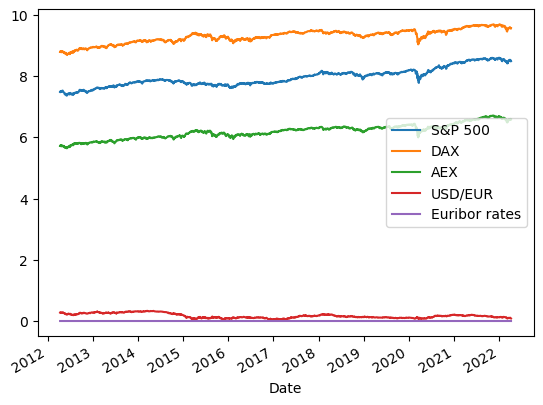

In [211]:
log_data = data
log_data[data.columns[:-1]] = np.log(data[data.columns[:-1]])

log_data.plot()

# Declaring Loss Operator

In [212]:
def loss_operator(Z, weights, Value: float = 10 ** 8):
    """
    The loss distribution is the weighted sum of negative log returns (X) multiplied by exp(Z(t) - Z(0)) where Z(x) is the log price at time x

    NOTE: For us, Z(0) = 0 as I standardised all returns at t = 0
    """
    loss = np.zeros(len(Z) - 1)
    loss_ind = Z[:-1].copy()
    T = len(Z) - 1
    t = np.arange(T)
    for Z_k, weight, name in zip(Z.values.T, weights, Z.columns):
        X_k = np.diff(Z_k)
        X_k = np.array([0] + X_k.tolist())
        X_k_shifted = X_k[1:] # from t = 2 to T
        X_k = X_k[:-1]  # from t = 1 to T - 1
        Z_k = Z_k[:-1]
        if name == 'S&P 500':
            # Include EUR/USD exposure
            loss_sub = Value * weight * np.exp((Z_k - Z_k[0]) + (Z['USD/EUR'][:-1] - Z['USD/EUR'][0])) * X_k_shifted
        elif name == 'Euribor rates':
            # The time risk
            w = Value * np.exp(Z_k[0])
            loss_sub = -w * np.exp(-(T-t) * Z_k) * Z_k

            # Add credit risk
            loss_sub += Value * weight * np.exp(Z_k[0] - (T - t) * Z_k) * (T - t) * X_k
        else:
            loss_sub = Value * weight * np.exp(Z_k - Z_k[0]) * X_k_shifted
        loss += loss_sub
        loss_ind[name] = loss_sub * (1 / (weight)) if name != 'USD/EUR' else 0
    return -loss, -loss_ind

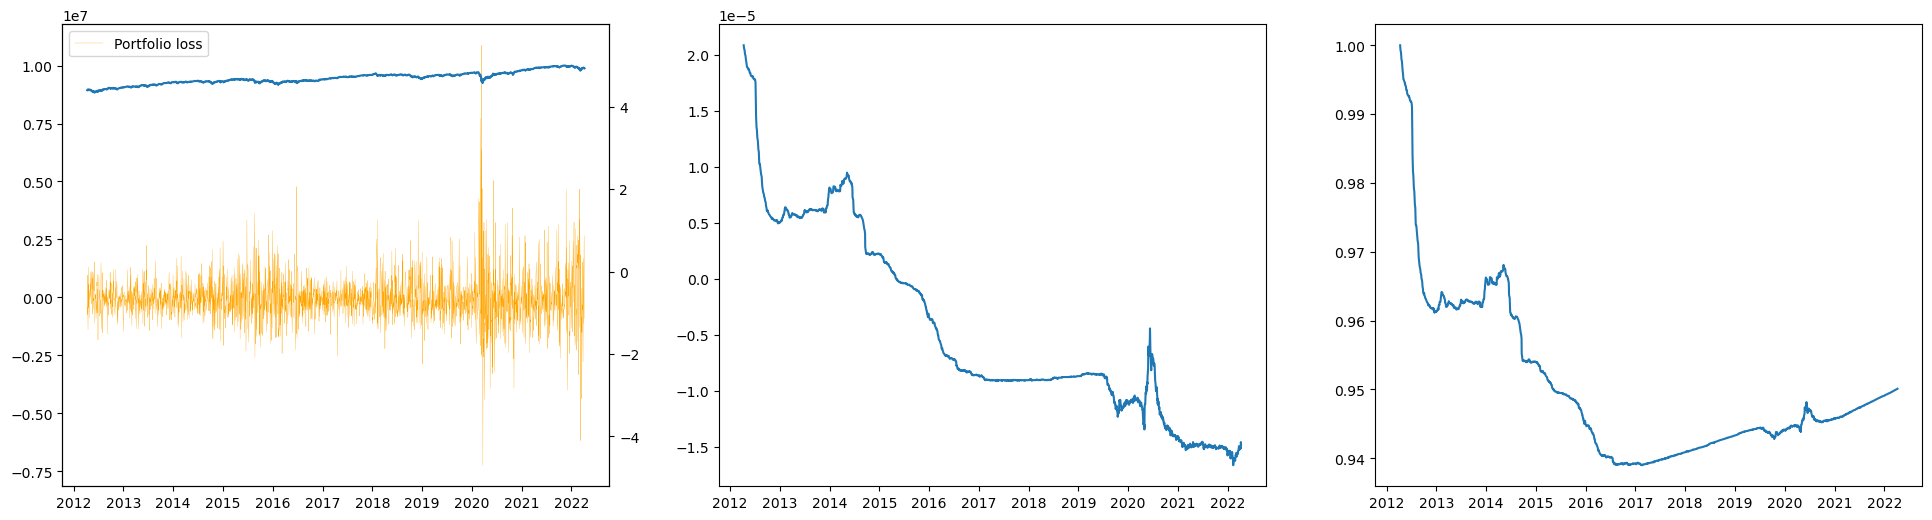

In [213]:
portfolio_loss, ind_loss = loss_operator(data, weights)

# # IT DOES NOT WORK
# # With just Inversed Returns
# ind_loss = -data
# portfolio_loss = ind_loss.dot(weights)

fig, axs = plt.subplots(1,3, figsize = (24, 6))
axs[0].plot(portfolio_loss, label = 'Portfolio loss', lw = 0.2, color='orange')
ax = axs[0].twinx()
PV = np.sum(weights * data, axis = 1)
ax.plot(PV)
ax.set_ylim(1.2 * max(-PV), 1.2 * max(PV))
axs[1].plot(data['Euribor rates'])
axs[2].plot(credit_val.loc[data.index])
axs[0].legend()
plt.show()

# Declaring methods to calculate VaR

### VaR CoVar

In [214]:
def Var_Cov_VaR(data: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    portfolio_VaR['VaR'] = pf_vol * dist(alpha, **kwargs)
    return portfolio_VaR.dropna()

def Var_Cov_ES(Vol: Any, alpha: float, dist: Callable, **kwargs) -> float:
    """
    Calculate the expected shortfall
    """
    alpha = 1 - alpha
    match dist:
        case stats.norm:
            q: float = stats.norm.isf(alpha)
            p: float = stats.norm.pdf(q)
            return Vol * p / (alpha)
        case stats.t:
            df: int | float = kwargs.get('df', 4)
            q: float = stats.t.ppf(alpha, df = df)
            p: float = stats.t.pdf(q, df = df)
            return Vol * ((df + (q ** 2)) / (df - 1)) * p / (alpha)
        case _:
            raise NotImplementedError()

In [215]:
window_size = 250 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

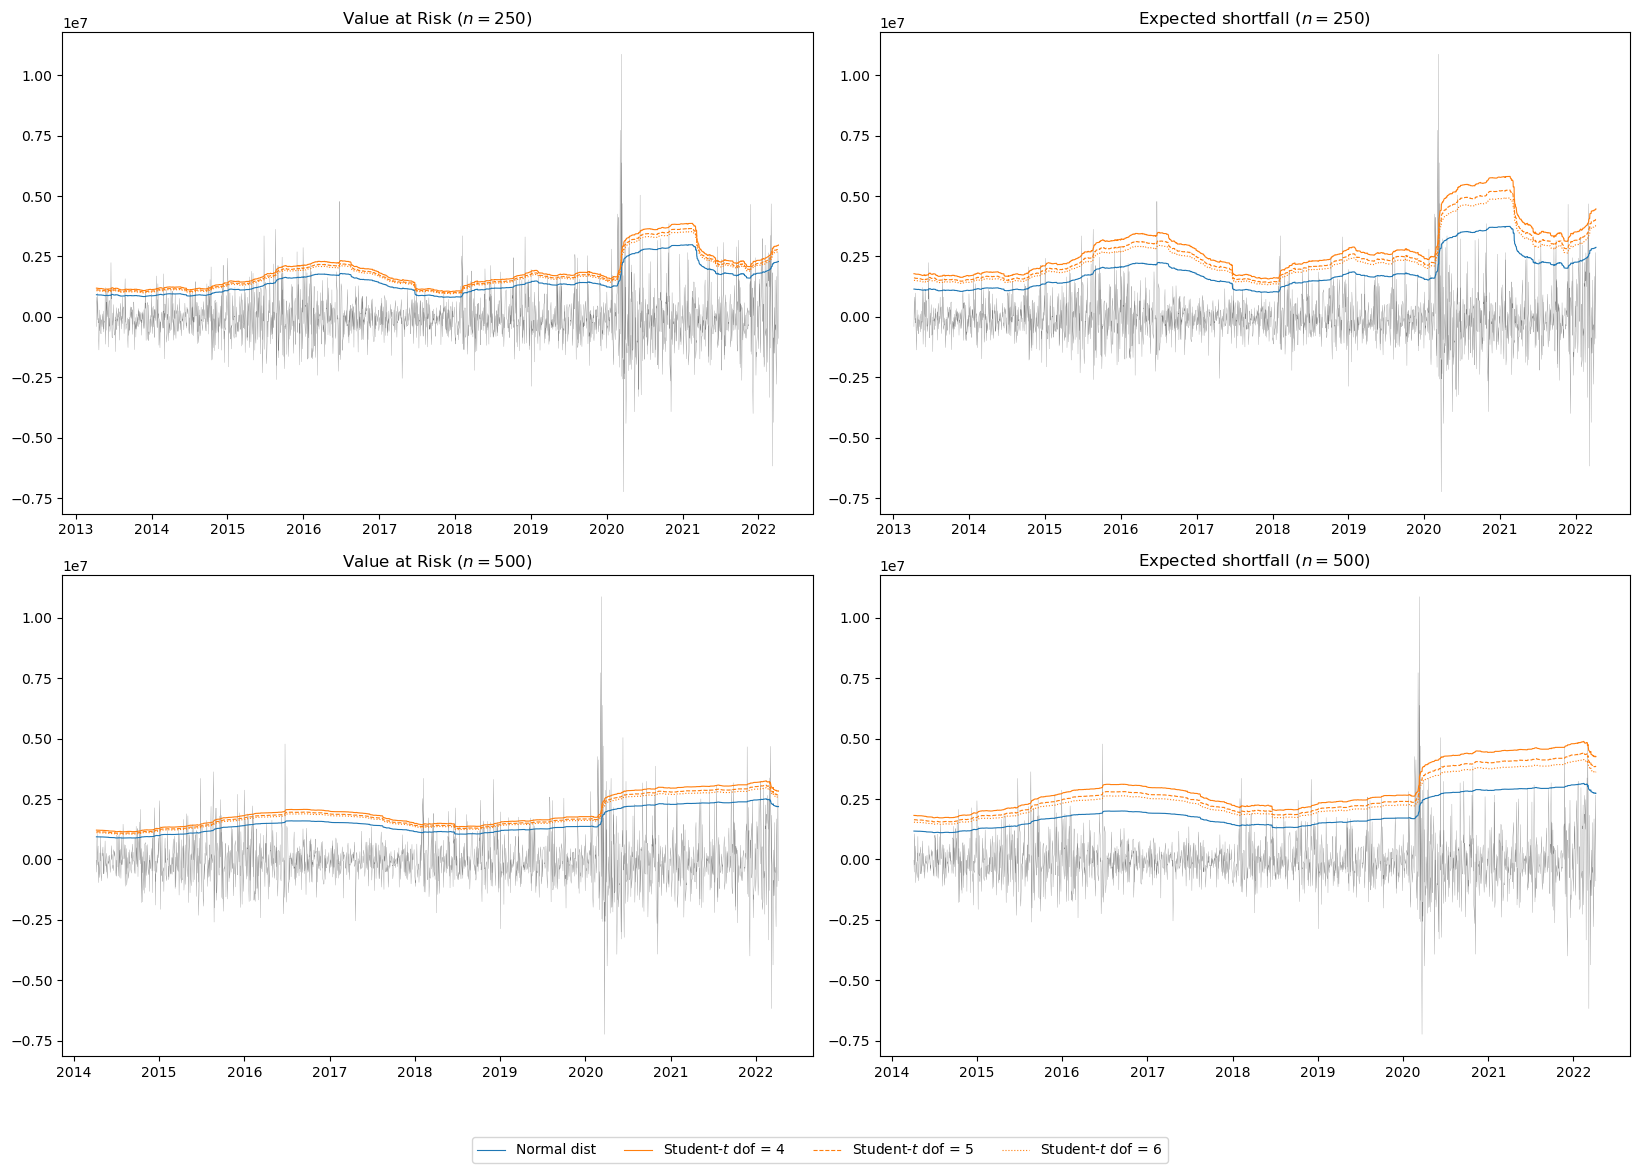

In [216]:
fig, axs = plt.subplots(2, 2, figsize = (16.5, 16.5 / 1.5)) #(8.2543, 8.2543 / 3)
axs[0,1].set_title('Expected shortfall $(n = 250)$')
axs[0,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[0,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0,0].set_title('Value at Risk $(n = 250)$')
axs[0,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[0,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[0,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[0,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[0,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)

window_size = 500 # days
VaR_HS_normal_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.norm.ppf)
VaR_HS_student4_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 4)
VaR_HS_student5_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 5)
VaR_HS_student6_1 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = .95, dist = stats.t.ppf, df = 6)

ES_HS_normal_1 = Var_Cov_ES(VaR_HS_normal_1.Vol, alpha = .95, dist = stats.norm)
ES_HS_student4_1 = Var_Cov_ES(VaR_HS_student4_1.Vol, alpha = .95, dist = stats.t, df = 4)
ES_HS_student5_1 = Var_Cov_ES(VaR_HS_student5_1.Vol, alpha = .95, dist = stats.t, df = 5)
ES_HS_student6_1 = Var_Cov_ES(VaR_HS_student6_1.Vol, alpha = .95, dist = stats.t, df = 6)

loss_df_sliced = portfolio_loss[window_size:]

axs[1,1].set_title('Expected shortfall $(n = 500)$')
axs[1,1].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,1].plot(ES_HS_normal_1, label = 'Normal dist', lw = .8)
axs[1,1].plot(ES_HS_student4_1, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,1].plot(ES_HS_student5_1, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,1].plot(ES_HS_student6_1, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[1,0].set_title('Value at Risk $(n = 500)$')
axs[1,0].plot(loss_df_sliced, lw = .2, c = 'black', alpha = .5)
axs[1,0].plot(VaR_HS_normal_1.VaR, label = 'Normal dist', lw = .8)
axs[1,0].plot(VaR_HS_student4_1.VaR, label = 'Student-$t$ dof = 4', c = 'C1', lw = .8)
axs[1,0].plot(VaR_HS_student5_1.VaR, label = 'Student-$t$ dof = 5', c = 'C1', ls = 'dashed', lw = .8)
axs[1,0].plot(VaR_HS_student6_1.VaR, label = 'Student-$t$ dof = 6', c = 'C1', ls = 'dotted', lw = .8)
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
fig.tight_layout()
plt.savefig('HS.pdf')
plt.show()

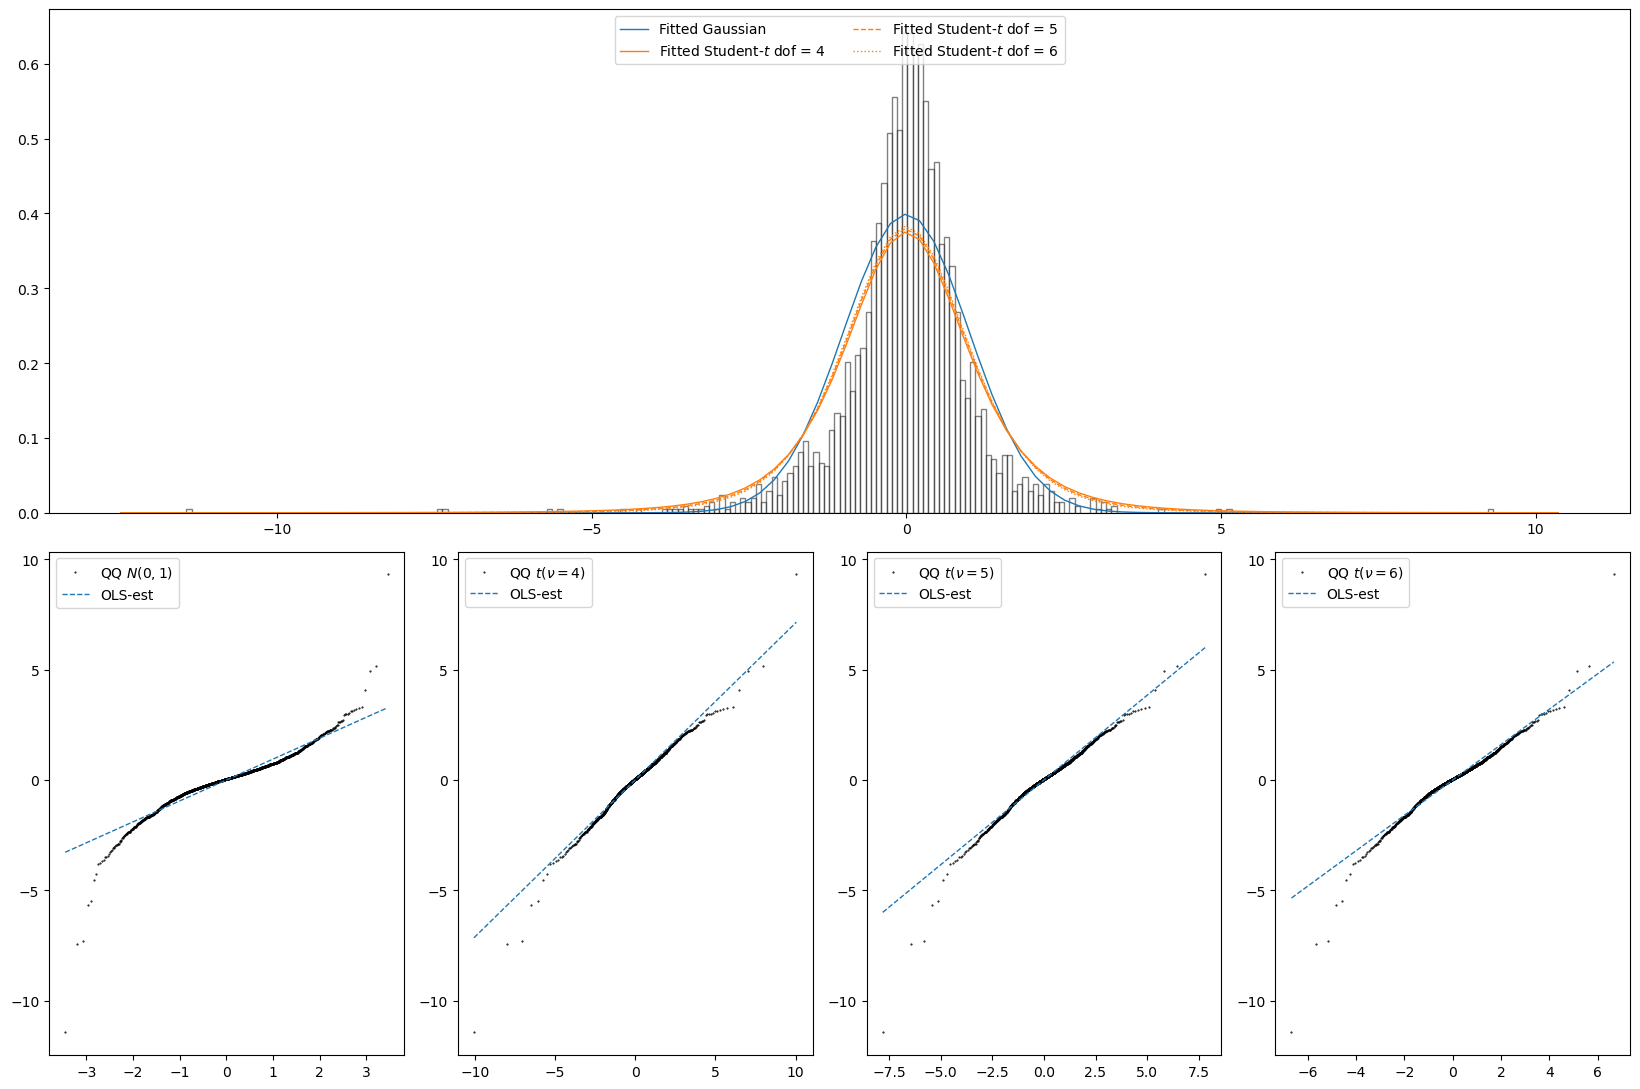

In [217]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import matplotlib as mpl

# Generate some random data
data = (log_data.diff() @ weights).dropna()
data = (data - data.mean()) / data.std()

# Create figure and subplots
# fig, axs = plt.subplots(2, 4, figsize=(12, 5))

# Plot histogram with density curve
fig = plt.figure(figsize = (16.5, 16.5 / 1.5))
gs = mpl.gridspec.GridSpec(2, 4)#, wspace=0.25, hspace=0.25) # 2x2 grid
axs = fig.add_subplot(gs[0, :]) # first row, first col
axs1 = fig.add_subplot(gs[1, 1]) # first row, second col
axs2 = fig.add_subplot(gs[1, 2])
axs3 = fig.add_subplot(gs[1, 3])
axs4 = fig.add_subplot(gs[1, 0])


axs.hist(data, bins=250, density=True, alpha=0.5, color='white', edgecolor='black')
xmin, xmax = axs.get_xlim()
x = np.linspace(xmin, xmax, 100)
pdf = stats.norm.pdf(x)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Gaussian')
pdf = stats.t.pdf(x, loc = np.mean(data), scale = np.std(data), df = 4)
axs.plot(x, pdf, linewidth=1, ls = '-', label = 'Fitted Student-$t$ dof = 4', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs1, sparams = (4,))
axs1.get_lines()[1].set_color('C0')
axs1.get_lines()[1].set_linestyle('dashed')
axs1.get_lines()[1].set_linewidth(1)
axs1.get_lines()[0].set_marker('.')  # Set marker style to dots
axs1.get_lines()[0].set_color('black')  # Set marker color to black
axs1.get_lines()[0].set_markersize(1)  # Set marker size
# axs1.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 5)
axs.plot(x, pdf, linewidth=1, ls = 'dashed', label = 'Fitted Student-$t$ dof = 5', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs2, sparams = (5,))
axs2.get_lines()[1].set_color('C0')
axs2.get_lines()[1].set_linestyle('dashed')
axs2.get_lines()[1].set_linewidth(1)
axs2.get_lines()[0].set_marker('.')  # Set marker style to dots
axs2.get_lines()[0].set_color('black')  # Set marker color to black
axs2.get_lines()[0].set_markersize(1)  # Set marker size
# axs2.set_title('QQ Plot')

pdf = stats.t.pdf(x, df = 6)
axs.plot(x, pdf, linewidth=1, ls = 'dotted', label = 'Fitted Student-$t$ dof = 6', c = 'C1')
stats.probplot(data, dist=stats.t, plot=axs3, sparams = (6,))
axs3.get_lines()[1].set_color('C0')
axs3.get_lines()[1].set_linestyle('dashed')
axs3.get_lines()[1].set_linewidth(1)
axs3.get_lines()[0].set_marker('.')  # Set marker style to dots
axs3.get_lines()[0].set_color('black')  # Set marker color to black
axs3.get_lines()[0].set_markersize(1)  # Set marker size
# axs3.set_title('QQ Plot')

axs.legend(loc = 'upper center', ncol = 2)

# axs3.set_title('Histogram with Density')
# Plot QQ plot
stats.probplot(data, dist="norm", plot=axs4)
axs4.get_lines()[1].set_color('C0')
axs4.get_lines()[1].set_linestyle('dashed')
axs4.get_lines()[1].set_linewidth(1)
axs4.get_lines()[0].set_marker('.')  # Set marker style to dots
axs4.get_lines()[0].set_color('black')  # Set marker color to black
axs4.get_lines()[0].set_markersize(1)  # Set marker size
# axs4.set_title('QQ Plot')

axs1.set_xlabel(None)
axs2.set_xlabel(None)
axs3.set_xlabel(None)
axs4.set_xlabel(None)

axs1.set_ylabel(None)
axs2.set_ylabel(None)
axs3.set_ylabel(None)
axs4.set_ylabel(None)

axs1.set_title(None)
axs2.set_title(None)
axs3.set_title(None)
axs4.set_title(None)
# Adjust layout
# plt.tight_layout()
axs1.legend([r'QQ $t(\nu = 4)$','OLS-est'])
axs2.legend([r'QQ $t(\nu = 5)$','OLS-est'])
axs3.legend([r'QQ $t(\nu = 6)$','OLS-est'])
axs4.legend([r'QQ $N(0,1)$','OLS-est'])
# Show plot
plt.tight_layout()
plt.savefig('QQ.pdf')
plt.show()


### Other Methods

In [218]:
def volatility(omega, alpha, beta, x):
    # this function is the main volatility filter needed to obtain the results while estimating

    T =len(x)

    # Filter Volatility
    sig     = np.zeros(T)
    sig[0]  = np.var(x[:50], ddof = 0); #initialize volatility at unconditional variance

    # loop iteratively over the indices and define the volatilities in that way
    for t in range(0,T-1):
        if t % 365 == 0:
            if t != 0:
                omega = np.var(x[t - 365: t]) * (1 - alpha - beta)
        sig[t+1] = omega + alpha *  (x[t]**2) + beta * sig[t]

    return sig ** .5

def GARCH_portfolio_variance(data: pd.DataFrame, weights: np.array):
    CM: np.matrix | pd.DataFrame = data.corr().fillna(0)
    n: int = CM.shape[0]
    weights = np.array(weights)
    W = weights.reshape((n, 1)) * weights.reshape((1,len(weights)))
    CMU: np.matrix = CM * W
    
    vol_df = data * 0
    for asset in data.columns:
        x = data[asset]
        alpha, beta = .05, .93
        omega = np.var(x[:365]) * (1 - alpha - beta)
        vol_df[asset] = volatility(omega, alpha, beta, x)
      
    vol = []
    
    Sigm = vol_df.values
    for row in Sigm:
        # Variance as outer product of the weights with the covariance
        vol.append(row @ CMU @ row)
    return np.array(vol) ** .5

def GARCH_VaR(vol, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """
    return vol * dist(alpha, **kwargs)


def devol(data: pd.DataFrame, pf_loss, window_size: int, port_weights: np.array, alpha: float, dist: Callable, **kwargs) -> float | pd.DataFrame:
    """
    Calculate the Value at Risk metric using dist
    """

    pf_vol = [np.nan] * window_size
    for k in range(window_size, len(data)):
        COV = data[k - window_size: k].cov(ddof = 0)
        pf_vol.append(
            np.sqrt(port_weights @ COV @ port_weights)
        )

    pf_vol = np.array(pf_vol)
    
    # rolling_vol: pd.DataFrame = data.shift(-1).rolling(window = window_size).var(ddof = 0).shift(1).dropna()
    # portfolio_volatility: np.array | Any = rolling_vol.values @ port_weights
 
    portfolio_VaR = pd.DataFrame(pf_vol, index = data.index, columns = ['Vol'])
    return pf_loss / portfolio_VaR.Vol

In [219]:
def Historic_Simulation(portfolio_risk: pd.DataFrame, window_size: int, port_weights: np.array, alpha: float, **kwargs) -> float:
    """
    Calculate VaR and ES using historic simulation
    """

    # Calculate the volatility
    df = pd.DataFrame([], index = portfolio_risk.index, columns = ['VaR'])
    VaR = portfolio_risk.rolling(window = window_size).quantile(alpha)
    ES  = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk)):
        _ = portfolio_risk.iloc[k - window_size: k]
        _ = _[_ >= VaR.iloc[k]]
        ES.append(np.mean(_))
        
    df['VaR'] = VaR
    df['ES'] = ES
    return df.dropna()

def filtered_HS(portfolio_risk_ind, weights, _alpha, window_size):
    Devol = pd.DataFrame([], index = portfolio_risk_ind.index)
    Vol = pd.DataFrame([], index = portfolio_risk_ind.index)
    for col in portfolio_risk_ind.columns:
        # Filter the volatility for each individual asset using the EWMA method
        x = portfolio_risk_ind[col]
        alpha = .05
        beta = 1 - alpha
        omega = 0
        vol = volatility(omega, alpha, beta, x)
        Vol[f'Vol {col}'] = vol
        Devol[f'Devol {col}'] = portfolio_risk_ind[col] / vol 
    # Calculate the portfolio volatility (not sure if correct)
    Devol = Devol.fillna(0)
    df = pd.DataFrame([], index = portfolio_risk_ind.index, columns = ['VaR'])

    # Define a rolling window VaR estimator
    ES  = [np.nan] * window_size
    VaR = [np.nan] * window_size
    for k in range(window_size, len(portfolio_risk_ind)):
        # Get the window over the devol object, and multiply with the predicted volatility
        D = Devol.iloc[k - window_size: k] * Vol.iloc[k].values

        # get the returns and calculate the VaR
        portfolio_returns = D @ weights
        VaR.append(portfolio_returns.rolling(window = window_size).quantile(_alpha).iloc[-1])
        
        _ = portfolio_returns[portfolio_returns >= VaR[k]]
        # The expected shortfall is the mean of the returns conditional on exceeding the var
        ES.append(np.mean(_))
    df['VaR'] = VaR
    df['ES'] = np.array(ES)
    return df[window_size:]#.dropna()

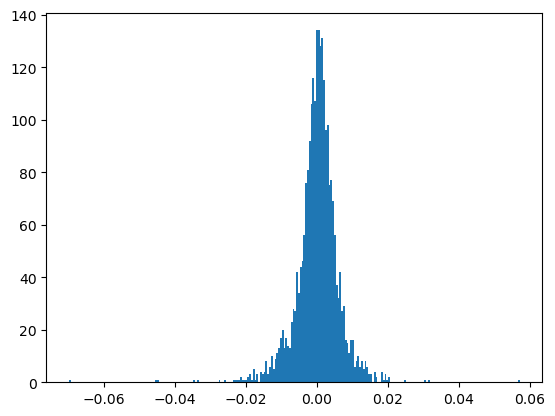

In [220]:
plt.hist(log_data.diff() @ weights, bins = 250)
plt.show()

In [221]:
VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, .95)

In [222]:
EWMA_HS = filtered_HS(ind_loss, weights, .95, window_size)
GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
VaR_GARCH = GARCH_VaR(GARCH, .95, stats.norm.ppf)
ES_GARCH = Var_Cov_ES(GARCH, .95, stats.norm)
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)

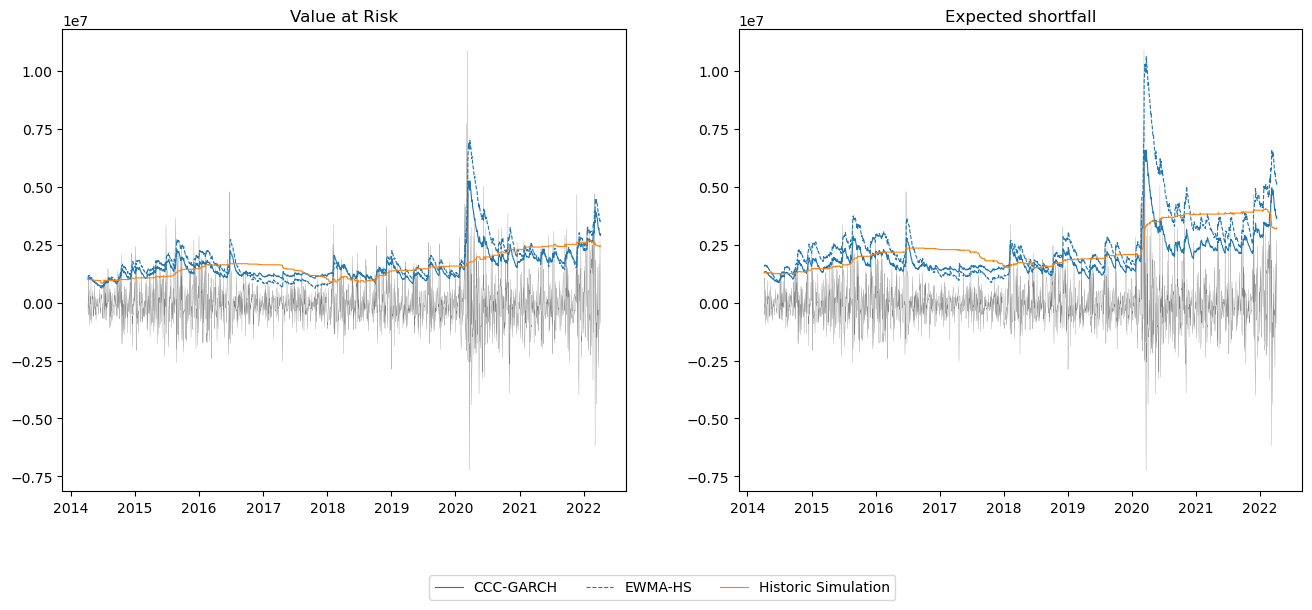

In [223]:
fig, axs = plt.subplots(1, 2, figsize = (16, 6))
# fig, axs = plt.subplots(1, 2, figsize = (8.2543, 8.2543 / 3))
axs[1].set_title('Expected shortfall')
axs[1].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[1].plot(portfolio_loss[window_size:].index, ES_GARCH[window_size:], label = 'CCC-GARCH', lw = .8, c = 'C0')
axs[1].plot(EWMA_HS.ES, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[1].plot(VaR_ES_Historic_Simulation.ES, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[1].plot(portfolio_sliced.index, ES_data_GARCH, label = 'GARCH', c = 'C2', ls = '-', lw = .8)
# axs[1].legend()

axs[0].set_title('Value at Risk')
axs[0].plot(portfolio_loss[window_size:], lw = .2, c = 'black', alpha = .5)
axs[0].plot(portfolio_loss[window_size:].index, VaR_GARCH[window_size:], label = 'CCC-GARCH', c = 'C0', lw = .8)
axs[0].plot(EWMA_HS.VaR, label = 'EWMA-HS', lw = .8, c = 'C0', ls = 'dashed')
axs[0].plot(VaR_ES_Historic_Simulation.VaR, label = 'Historic Simulation', lw = .8, c = 'C1')
# axs[0].legend(bbox_to_anchor=(0.5, -.3), loc='center', ncol=5)
lines_labels = [ax.get_legend_handles_labels() for ax in fig.axes][:1]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)][:2]
fig.legend(lines, labels, bbox_to_anchor=(0.5, -.05), loc='center', ncol=4)
plt.show()

# BackTesting

## Obtaining Data

In [224]:
# Function to obtain interarrival Rates
def calculate_distances(array):
    
    # Get indices of 1s
    ones_indices = np.where(array == 1)[0]
    
    # Calculate distances between consecutive indices of 1s
    if len(ones_indices) > 1:
        distances = np.diff(ones_indices)
    else:
        distances = []  # If there's only one or no 1 at all, no distances to calculate
    
    return distances

def Backtest(VaR, ES, Loss, VaR_alpha, qqplot_arrival=False):
    """
    Perform a t-test to assess the accuracy of the Expected Shortfall (ES) estimation at the confidence level.

    Parameters:
    - VaR: Array of VaR estimates at the 97.5% confidence level.
    - ES: Array of ES estimates at the 97.5% confidence level.
    - Loss: Distribution of Observed Losses.

    """
    # Tests for VaR
    Violations_VaR = Loss > VaR
    print("\nVaR Violations: ", sum(Violations_VaR))

    n = len(Violations_VaR)     # Number of trials
    p = 1-VaR_alpha              # Expected probability of violation per trial
    x = sum(Violations_VaR)     # Observed number of violations
    alpha = 0.05                # Significance level for the test

    # Calculate P-values for two-tail test
    p_value_left = stats.binom.cdf(x, n, p)  # Probability of x or fewer successes
    p_value_right = 1 - stats.binom.cdf(x - 1, n, p)  # Probability of x or more successes
    p_value = min(p_value_left, p_value_right) * 2  # Two-tailed P-value

    if p_value <= alpha:
        print("VaR Violations amount differs significantly from Expected")

    if qqplot_arrival == True:
        distances = calculate_distances(Violations_VaR)
        # Checking if distances array is not empty
        if len(distances) > 0:
            # Generate a QQ-plot
            plt.figure(figsize=(12, 12))
            sm.qqplot(distances, dist=stats.expon, line="q", ax=plt.subplot(1,1,1))
            plt.title('QQ-Plot: InterArrival Distance vs. Exponential Distribution')
            plt.show()
        else:
            print("Not enough data points (1s) to generate a QQ-plot.")

    # Tests for ES
    # As an average quantity it follows normal distribution, thus we can use t test
    
    average_Real_ES = np.mean(Loss[Violations_VaR])     # Calculate Real World ES (the mean loss where VaR violation occured)
    average_Theoretical_ES = np.mean(ES[Violations_VaR])    # ES obtained with the Prediction Method
    print("\nAverage ES Real and Theoretical: ", average_Real_ES, average_Theoretical_ES)

    # Calculate the two sample z-test to find if they follow different distributions
    standard_error = np.std(Loss[Violations_VaR]) / np.sqrt(np.sum(Violations_VaR))
    # Compute the z-test statistic
    Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
    ES_p = stats.norm.sf(abs(Z_Test_ES)) * 2     # Calculate the two-sided p-value from the t-test statistic
    print("ES t-Test significance of difference: ", ES_p, " | Reject if <0.05\n\n")

    return

In [225]:
data = log_data
# Weights, if we use as Daan derived (Converting $ currencies to EUR)
weights = [.2, .2, .2, .0, .4]

start_date = '2012-01-01'
end_date = '2023-01-01'
data = data[(data.index >= pd.to_datetime(start_date)) & (data.index < pd.to_datetime(end_date))]        # Keeping only the related dates

# With Loss Operator
portfolio_loss, ind_loss = loss_operator(data, weights)

# # IT DOES NOT WORK
# # With just Inversed Returns
# ind_loss = -data
# portfolio_loss = ind_loss.dot(weights)


In [226]:
# Obtaining Correct windows for Year Sizes

dates = data.index
indexes_year_changes = []
for i in range(len(dates)-1):           # Just scanning where date year index changes
    if dates[i+1].year != dates[i].year:
        indexes_year_changes.append(i+1)
indexes_year_changes.append(len(dates)-1)
print("Indexes where year changes: ", indexes_year_changes)

window_size = 242                           # The only way for us to match their amount of used days in the first year is to use this strange number as window
portfolio_loss_backtest = portfolio_loss[window_size:]          # We do not need to compare these days
indexes_year_changes = np.subtract(indexes_year_changes, window_size)   # Updating indexes so that first period is not included
indexes_year_changes = np.add(indexes_year_changes, 1)                  # Updating indexes so that they can be looped
indexes_year_changes[0] = 0

Indexes where year changes:  [183, 435, 687, 939, 1191, 1442, 1693, 1945, 2198, 2450, 2517]


## VaR_975

In [227]:
alpha = .975

### Var-CoVar


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  7

Average ES Real and Theoretical:  1364259.3385160584 1237729.6135073232
ES t-Test significance of difference:  0.39390992418045156  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  13
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  1608996.236978687 1353964.7295377082
ES t-Test significance of difference:  0.016169035391752573  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  14
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2314793.5661294176 1993521.8386947662
ES t-Test significance of difference:  0.05590942255436881  | Reject

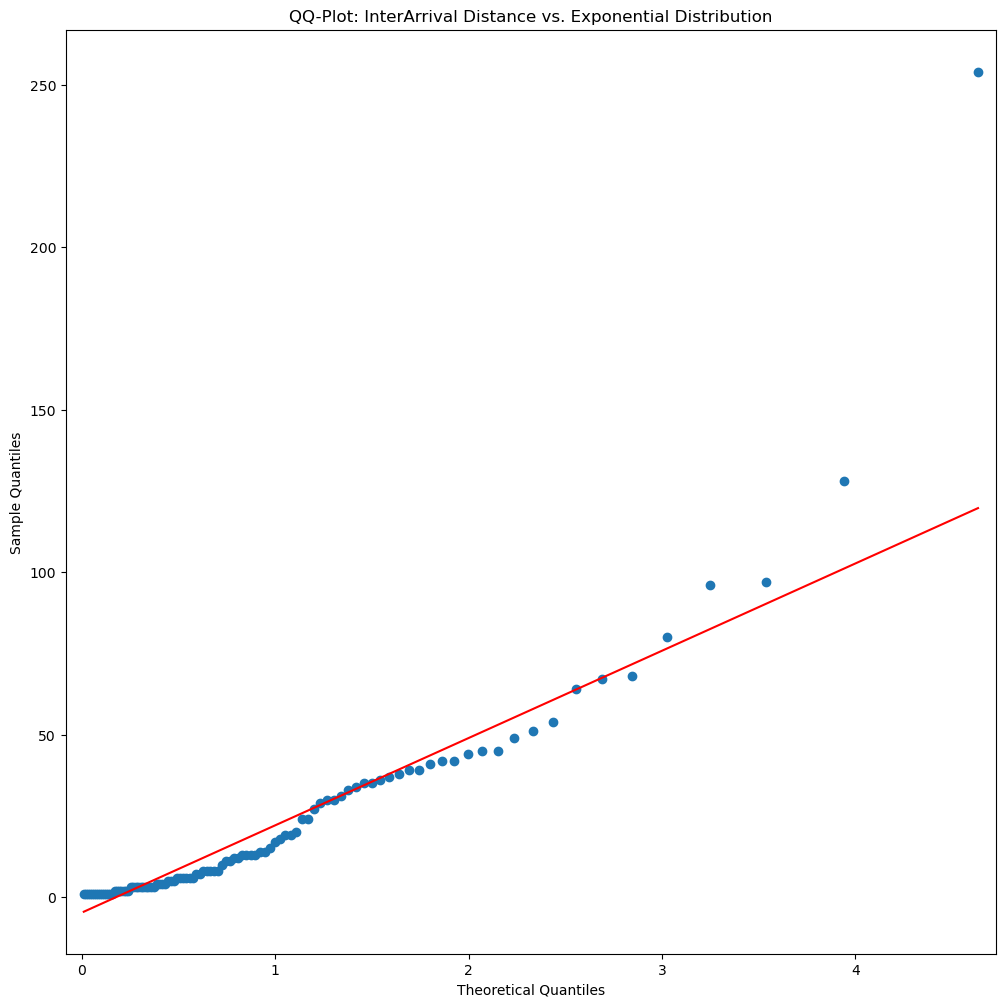


Average ES Real and Theoretical:  2494765.6727077803 1981668.1838411705
ES t-Test significance of difference:  0.00018765767930402225  | Reject if <0.05




In [228]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  2

Average ES Real and Theoretical:  1914152.3385677969 2099651.3057546006
ES t-Test significance of difference:  0.43053270303349733  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  5

Average ES Real and Theoretical:  2022900.9134909448 2366841.018542738
ES t-Test significance of difference:  0.0034713635830429957  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  4

Average ES Real and Theoretical:  3088303.44759398 3544844.0590912295
ES t-Test significance of difference:  0.03587707099888952  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.975 | period=2016 | Trading Days=252

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


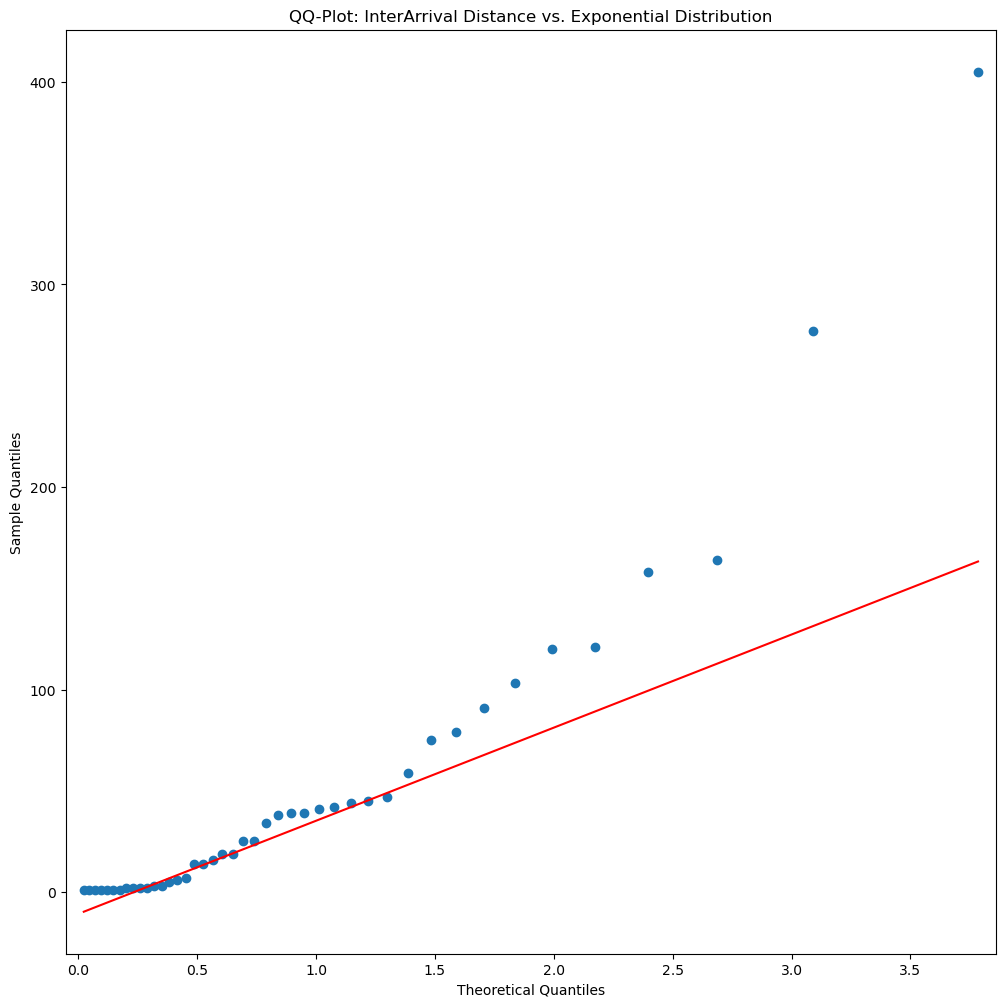


Average ES Real and Theoretical:  3246799.229526837 3396811.5329782306
ES t-Test significance of difference:  0.5644015330047857  | Reject if <0.05




In [229]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  2

Average ES Real and Theoretical:  1914152.3385677969 1851503.4077242902
ES t-Test significance of difference:  0.7900640105309766  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  7

Average ES Real and Theoretical:  1874330.1690568961 2046850.8556334355
ES t-Test significance of difference:  0.1593873029769638  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  6

Average ES Real and Theoretical:  2823245.0043956568 3073272.3486686177
ES t-Test significance of difference:  0.27959519634989405  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.975 | period=2016 | Trading Days=252


C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


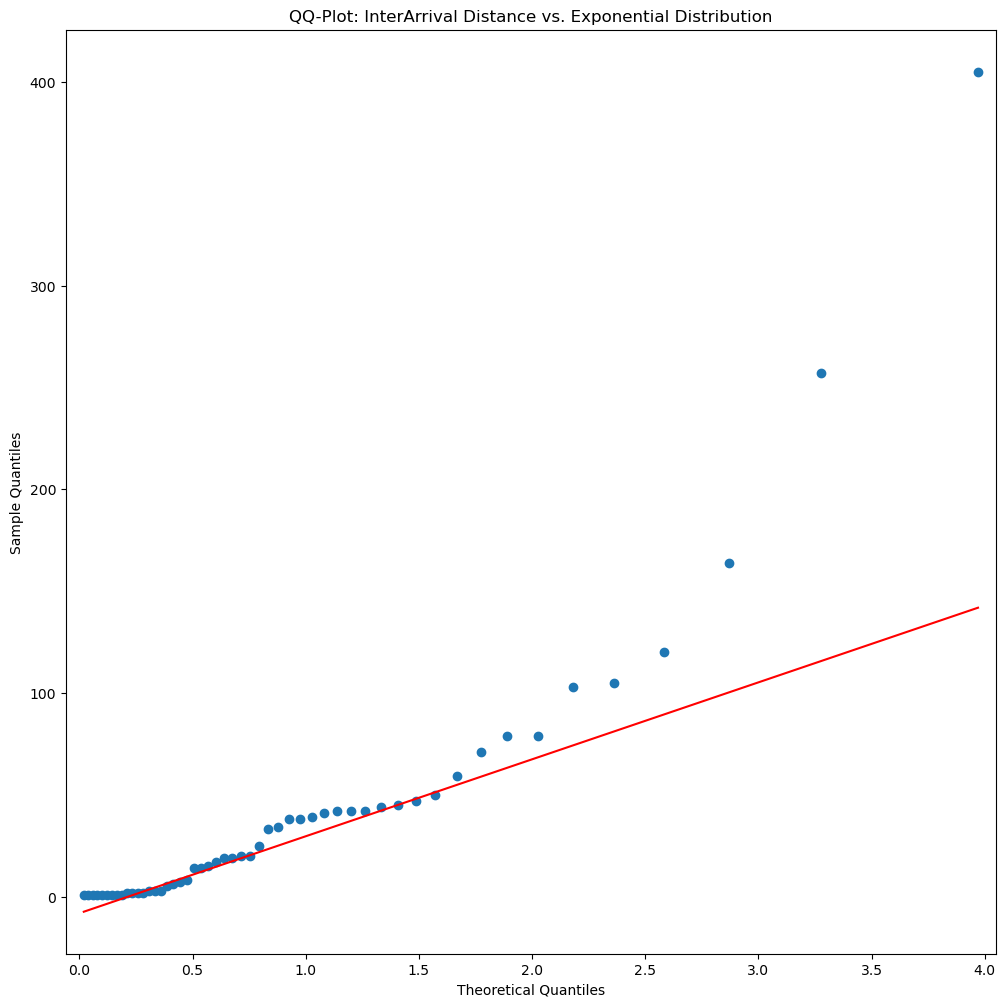


Average ES Real and Theoretical:  3074593.1312221577 2981998.238511247
ES t-Test significance of difference:  0.6806150459844913  | Reject if <0.05




In [230]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  2

Average ES Real and Theoretical:  1914152.3385677969 1711952.998536503
ES t-Test significance of difference:  0.3902032235370092  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  9

Average ES Real and Theoretical:  1762562.6644547887 1872859.9711383884
ES t-Test significance of difference:  0.35040333310920935  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  9

Average ES Real and Theoretical:  2601717.057016824 2814251.294001525
ES t-Test significance of difference:  0.2721597302685915  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.975 | period=2016 | Trading Days=252
Exp

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


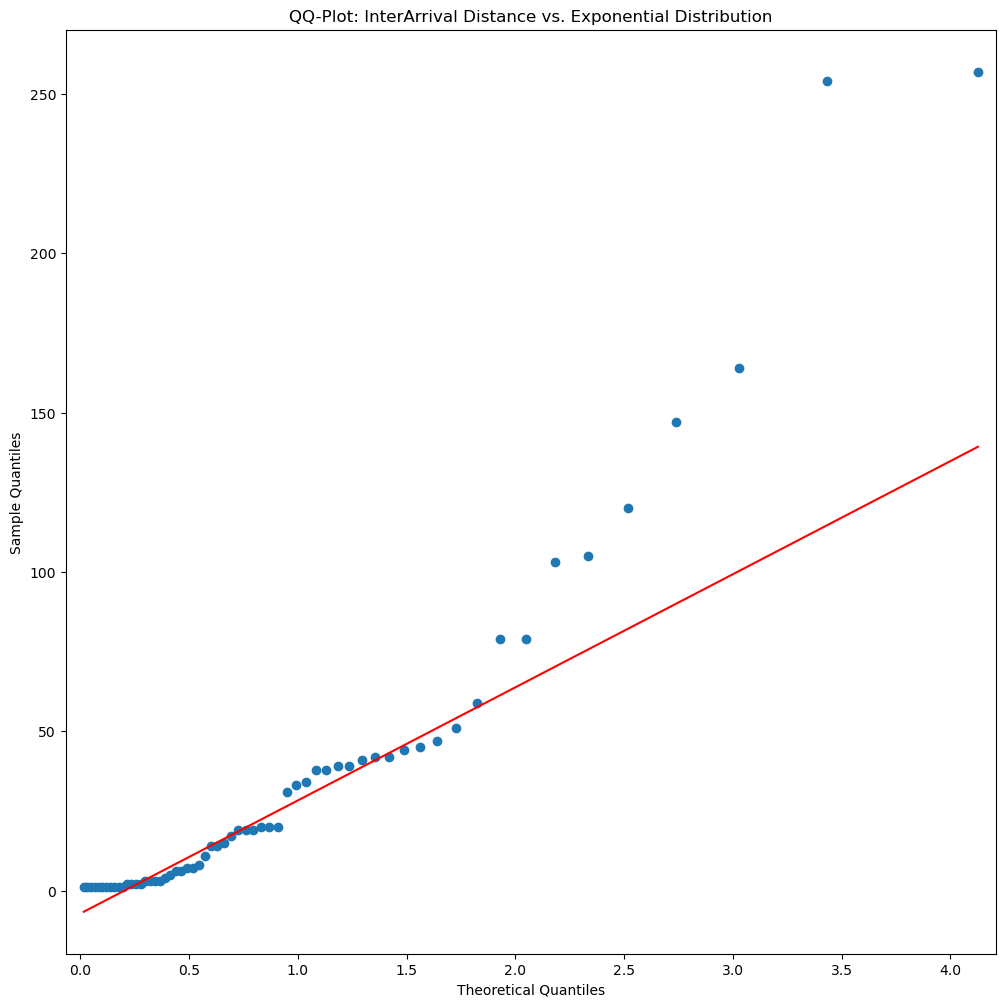


Average ES Real and Theoretical:  2913402.5101682646 2725795.747421485
ES t-Test significance of difference:  0.3508212950298957  | Reject if <0.05




In [231]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  5

Average ES Real and Theoretical:  1457747.6742956904 1288995.3775929702
ES t-Test significance of difference:  0.3794677414937687  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  11

Average ES Real and Theoretical:  1693662.4078044312 1557357.0857686691
ES t-Test significance of difference:  0.20308964100693427  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  11

Average ES Real and Theoretical:  2472407.180090216 2341617.6177587197
ES t-Test significance of difference:  0.4703255019036995  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2016 | Trading Days=252
Expected number of VaR violations: 

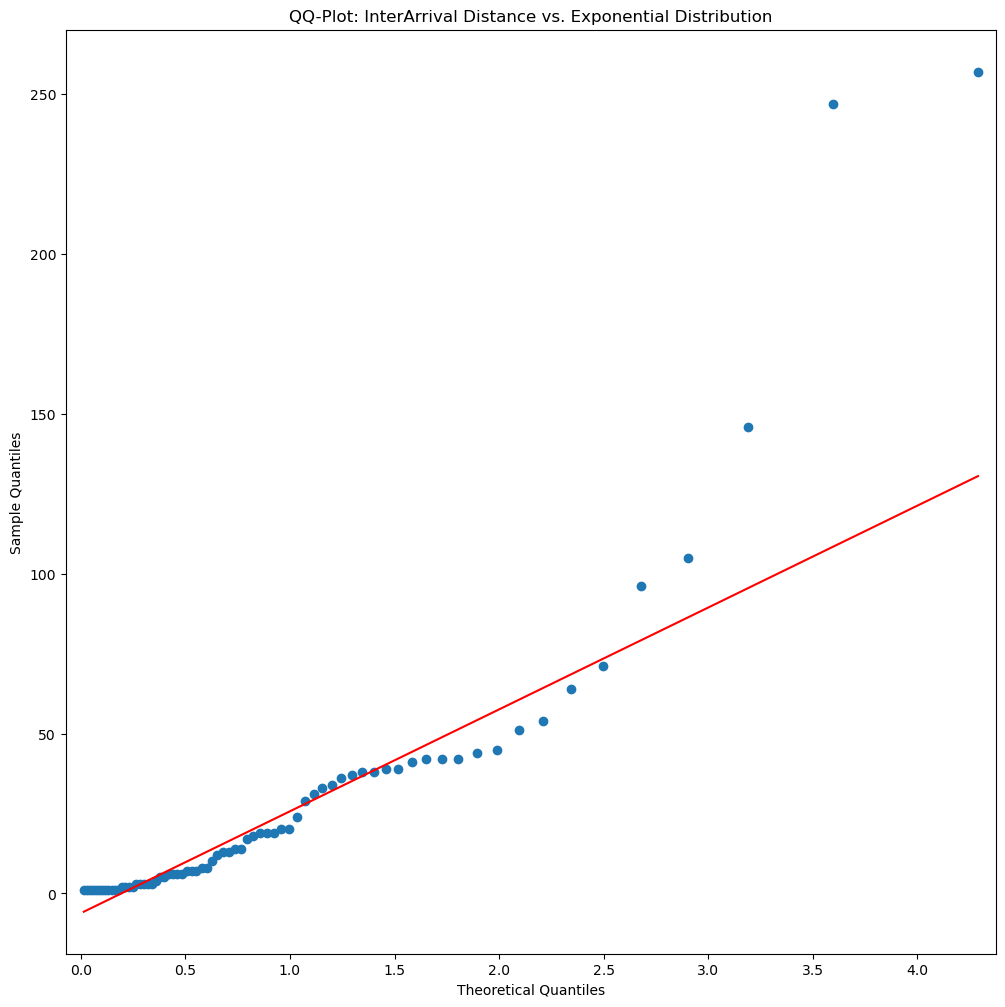


Average ES Real and Theoretical:  2745089.504802137 2551638.2381439027
ES t-Test significance of difference:  0.28437442845260685  | Reject if <0.05




In [232]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[1]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  6

Average ES Real and Theoretical:  1395162.4361304648 1215442.5953196601
ES t-Test significance of difference:  0.29015149098541226  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  12

Average ES Real and Theoretical:  1595110.808240303 1379507.6317983123
ES t-Test significance of difference:  0.08046087012629395  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  11

Average ES Real and Theoretical:  2454731.306043243 2106272.320393826
ES t-Test significance of difference:  0.0596159103883839  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2016 | Trading Days=252
Expected number of VaR violations: 6

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


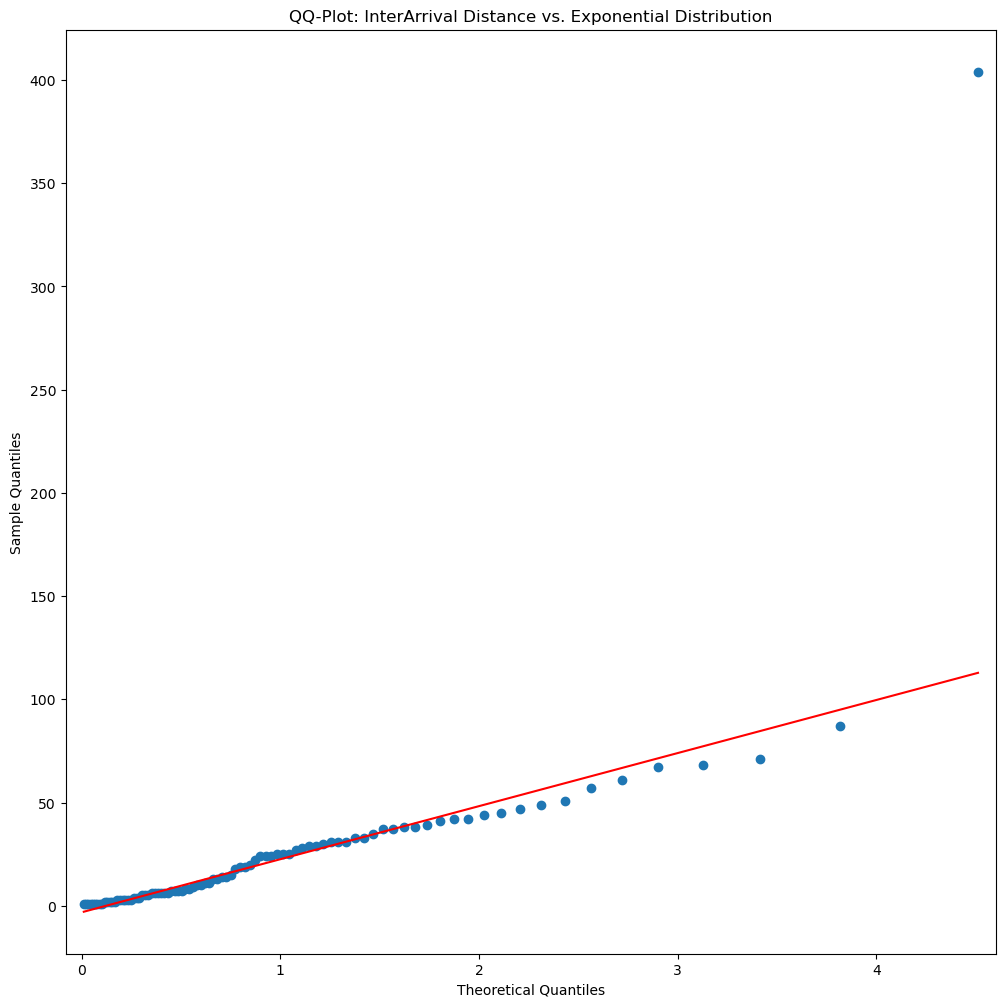


Average ES Real and Theoretical:  2504850.1516889133 2097415.1920207976
ES t-Test significance of difference:  0.0070230744853424665  | Reject if <0.05




In [233]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.975 | period=2013 | Trading Days=194
Expected number of VaR violations: 4.850000000000004

VaR Violations:  4

Average ES Real and Theoretical:  1531560.6043794374 1278998.4425086542
ES t-Test significance of difference:  0.26338702331626673  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2014 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  11

Average ES Real and Theoretical:  1562761.4955125987 1646096.6455933193
ES t-Test significance of difference:  0.569374763514884  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2015 | Trading Days=252
Expected number of VaR violations: 6.300000000000006

VaR Violations:  5

Average ES Real and Theoretical:  3009836.272381867 2735885.205659169
ES t-Test significance of difference:  0.14437285390168808  | Reject if <0.05



Variance Covariance Normal | VaR0.975 | period=2016 | Trading Days=252
Expected number of VaR violations: 6.

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


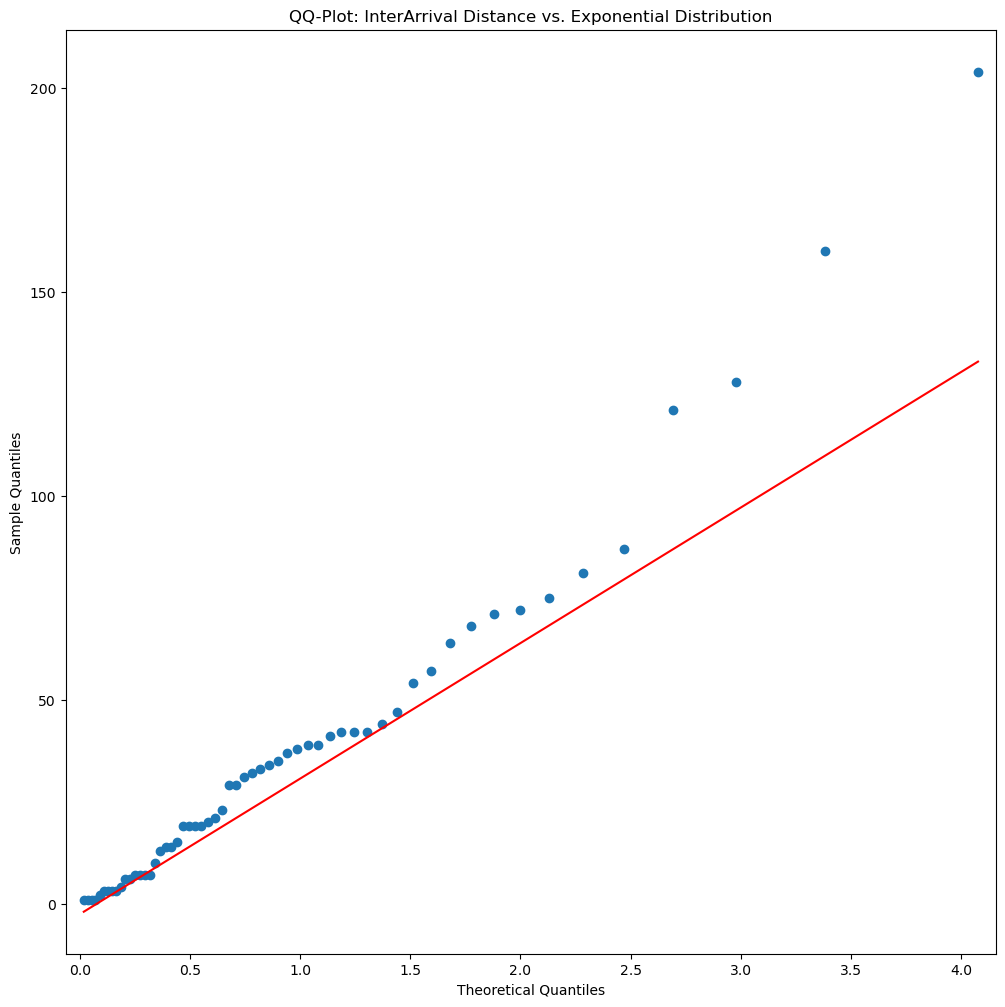


Average ES Real and Theoretical:  2462449.2057925384 2252578.0039066784
ES t-Test significance of difference:  0.3220725642251392  | Reject if <0.05




In [234]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

## VaR_99

In [235]:
alpha = .99

### Var-CoVaR


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  3

Average ES Real and Theoretical:  1681335.3907378044 1398421.6917820487
ES t-Test significance of difference:  0.2510249403025392  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  9
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  1762562.6644547887 1532967.256880573
ES t-Test significance of difference:  0.05191744143632344  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  10
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  2507231.817452241 2257507.4358250215
ES t-Test significance of difference:  0.20240091161217222  | Reject if 

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


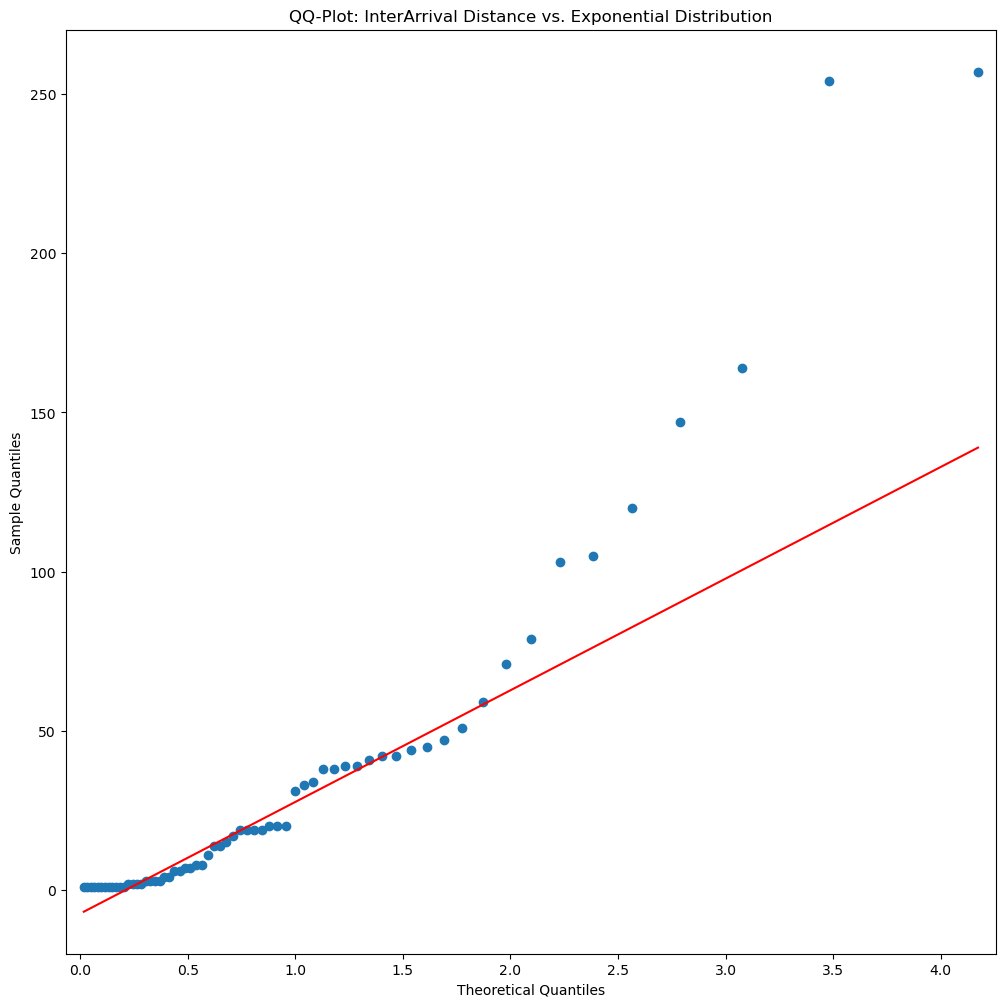


Average ES Real and Theoretical:  2856639.841069345 2215657.5553140305
ES t-Test significance of difference:  0.000996239542236938  | Reject if <0.05




In [236]:
# For each period we find amount of VaR violations

HS_Norm = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.norm.ppf)
VaR_HS_normal = HS_Norm.VaR
ES_HS_normal = Var_Cov_ES(HS_Norm.Vol, alpha = alpha, dist = stats.norm)
VaR = VaR_HS_normal
ES = ES_HS_normal

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=4


Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  1

Average ES Real and Theoretical:  2246946.546596485 2757573.1752000083
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  0

Average ES Real and Theoretical:  nan nan
ES t-Test significance of difference:  nan  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  2

Average ES Real and Theoretical:  3491561.765399467 4396097.338341538
ES t-Test significance of difference:  9.056099257419034e-21  | Reject if <0.05



Variance Covariance t-Student_DoF=4 | VaR0.99 | period=2016 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Vio

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


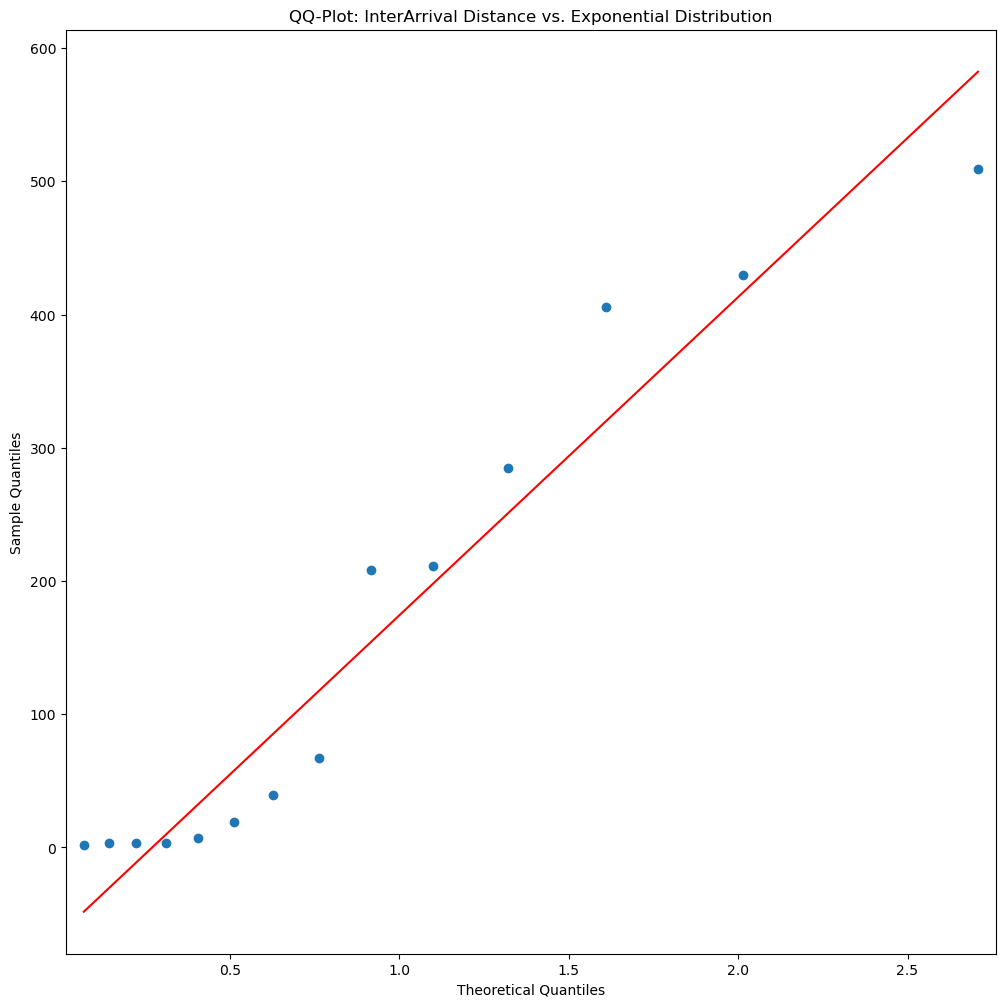


Average ES Real and Theoretical:  4581350.991251555 4550479.241560071
ES t-Test significance of difference:  0.9563227058456716  | Reject if <0.05




In [237]:
# For each period we find amount of VaR violations

dof = 4
HS_student4 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student4 = HS_student4.VaR
ES_HS_student4 = Var_Cov_ES(HS_student4.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student4
ES = ES_HS_student4

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=4 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=5


Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  1

Average ES Real and Theoretical:  2246946.546596485 2351824.7433297667
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  3

Average ES Real and Theoretical:  2212361.537275649 2773839.094974104
ES t-Test significance of difference:  4.637225665820525e-10  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  2

Average ES Real and Theoretical:  3491561.765399467 3749256.987041831
ES t-Test significance of difference:  0.007750322832313961  | Reject if <0.05



Variance Covariance t-Student_DoF=5 | VaR0.99 | period=2016 | Trading Days=252
Expected number o

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


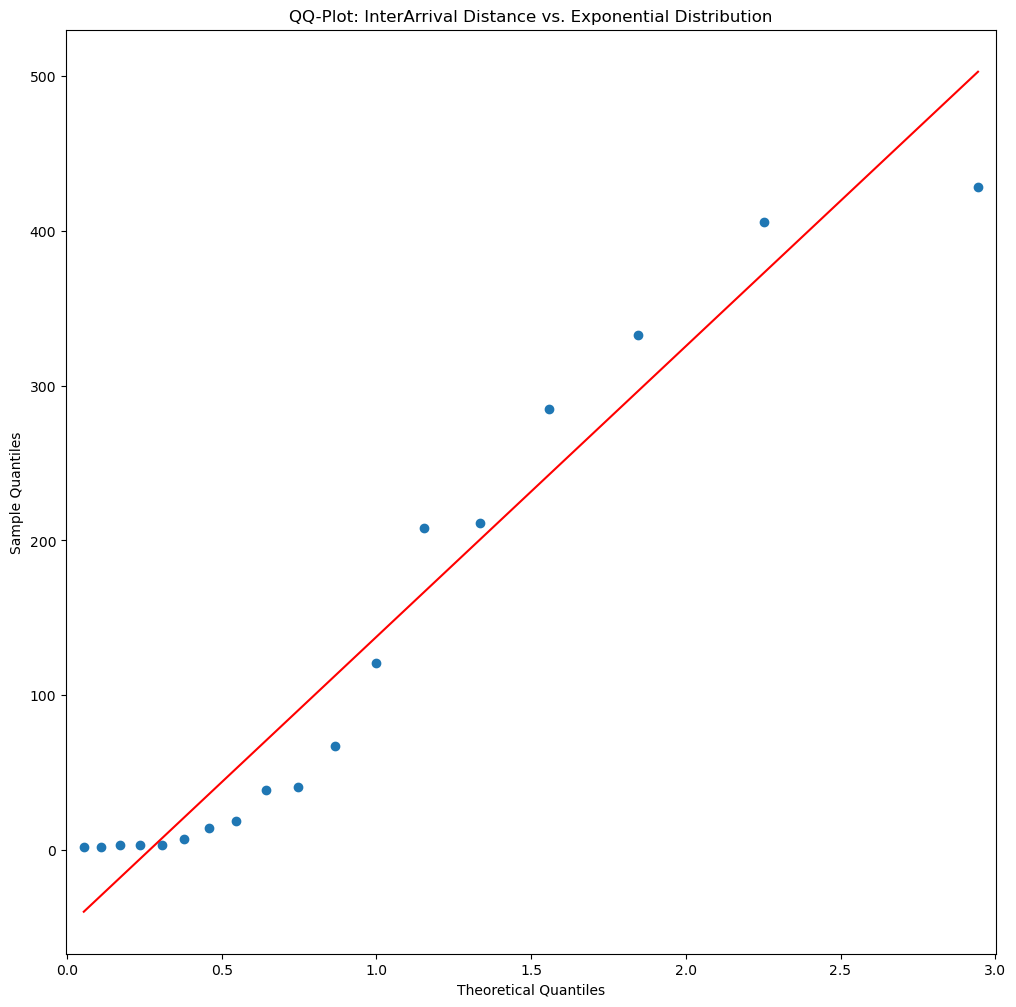


Average ES Real and Theoretical:  4213225.448425658 3819744.0108405477
ES t-Test significance of difference:  0.41969993521360516  | Reject if <0.05




In [238]:
# For each period we find amount of VaR violations

dof = 5
HS_student5 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student5 = HS_student5.VaR
ES_HS_student5 = Var_Cov_ES(HS_student5.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student5
ES = ES_HS_student5

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=5 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### t-Student_dof=6


Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  1

Average ES Real and Theoretical:  2246946.546596485 2130027.9323171447
ES t-Test significance of difference:  0.0  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  4

Average ES Real and Theoretical:  2105043.294839701 2442958.123672181
ES t-Test significance of difference:  0.00327616366951962  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  2

Average ES Real and Theoretical:  3491561.765399467 3395670.5874807346
ES t-Test significance of difference:  0.3217632839797755  | Reject if <0.05



Variance Covariance t-Student_DoF=6 | VaR0.99 | period=2016 | Trading Days=252
Expected number of V

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


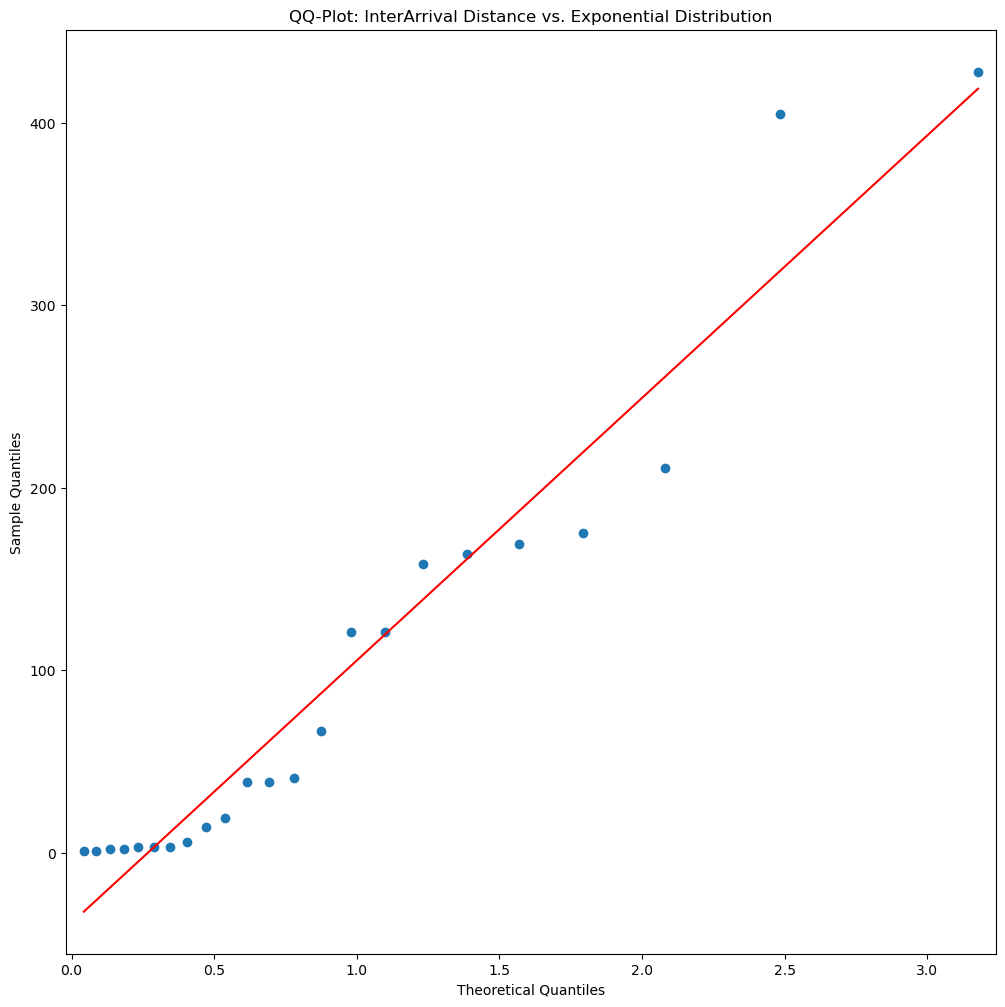


Average ES Real and Theoretical:  3811379.18975771 3338190.4880904425
ES t-Test significance of difference:  0.26037656034713486  | Reject if <0.05




In [239]:
# For each period we find amount of VaR violations

dof = 6
HS_student6 = Var_Cov_VaR(ind_loss, window_size = window_size, port_weights = weights, alpha = alpha, dist = stats.t.ppf, df = dof)
VaR_HS_student6 = HS_student6.VaR
ES_HS_student6 = Var_Cov_ES(HS_student6.Vol, alpha = alpha, dist = stats.t, df = dof)
VaR = VaR_HS_student6
ES = ES_HS_student6

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance t-Student_DoF=6 | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### Historic Simulation


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  3

Average ES Real and Theoretical:  1681335.3907378044 1513624.0899004831
ES t-Test significance of difference:  0.4962172320610275  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  6

Average ES Real and Theoretical:  1943726.1112618435 1898731.6564976398
ES t-Test significance of difference:  0.7118783396524826  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  6

Average ES Real and Theoretical:  2873692.0104703214 2996288.1974696964
ES t-Test significance of difference:  0.5394123619678064  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2016 | Trading Days=252
Expected number of VaR violations: 2.5

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


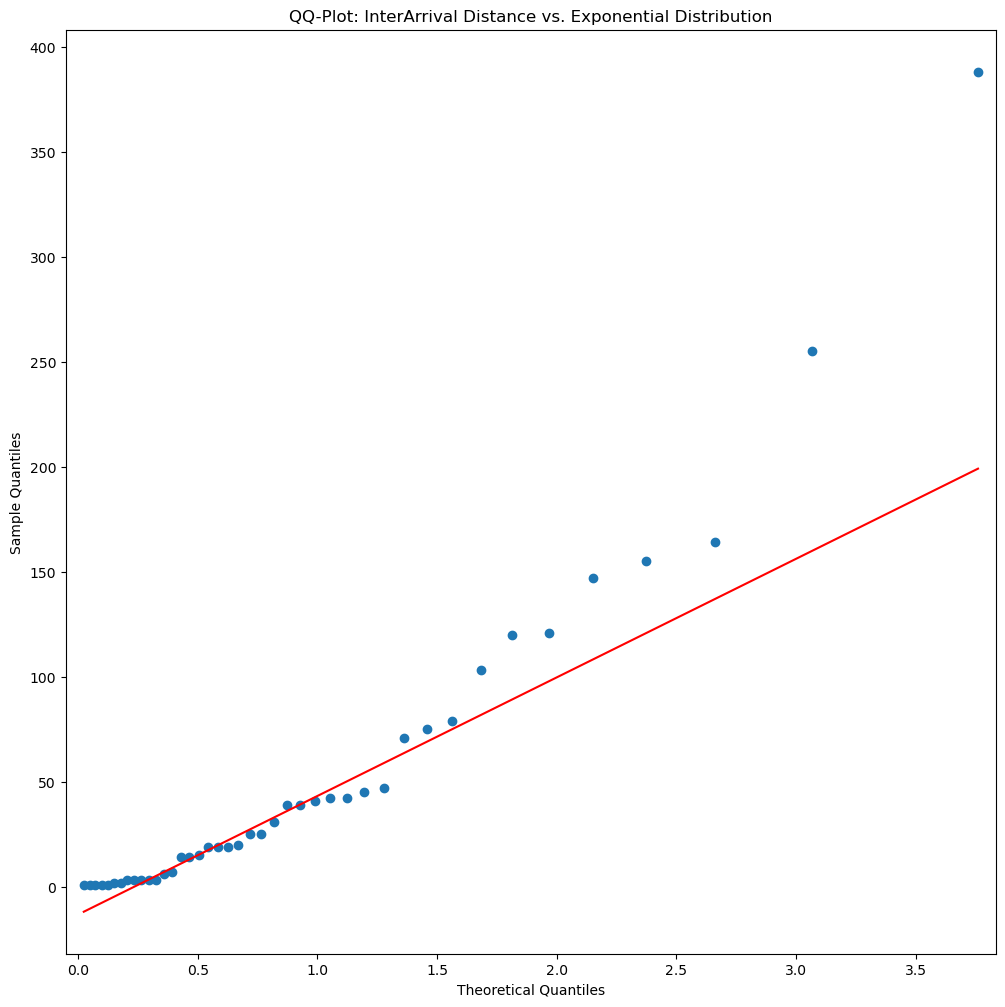


Average ES Real and Theoretical:  3004020.4130995157 2884496.8974129455
ES t-Test significance of difference:  0.6627970503217957  | Reject if <0.05




In [240]:
# For each period we find amount of VaR violations

VaR_ES_Historic_Simulation = Historic_Simulation(portfolio_loss, window_size, weights, alpha)
VaR_Historic_Simulation = VaR_ES_Historic_Simulation.VaR
ES_Historic_Simulation = VaR_ES_Historic_Simulation.ES
VaR = VaR_Historic_Simulation
ES = ES_Historic_Simulation

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### CCC - GARCH


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  4

Average ES Real and Theoretical:  1531560.6043794374 1321325.6188028888
ES t-Test significance of difference:  0.3518618557790625  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  8
VaR Violations amount differs significantly from Expected

Average ES Real and Theoretical:  1811333.0919368982 1648267.846822752
ES t-Test significance of difference:  0.18277663481729944  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  6

Average ES Real and Theoretical:  2873692.0104703214 2411489.7201617174
ES t-Test significance of difference:  0.020682569684680397  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=20

c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error


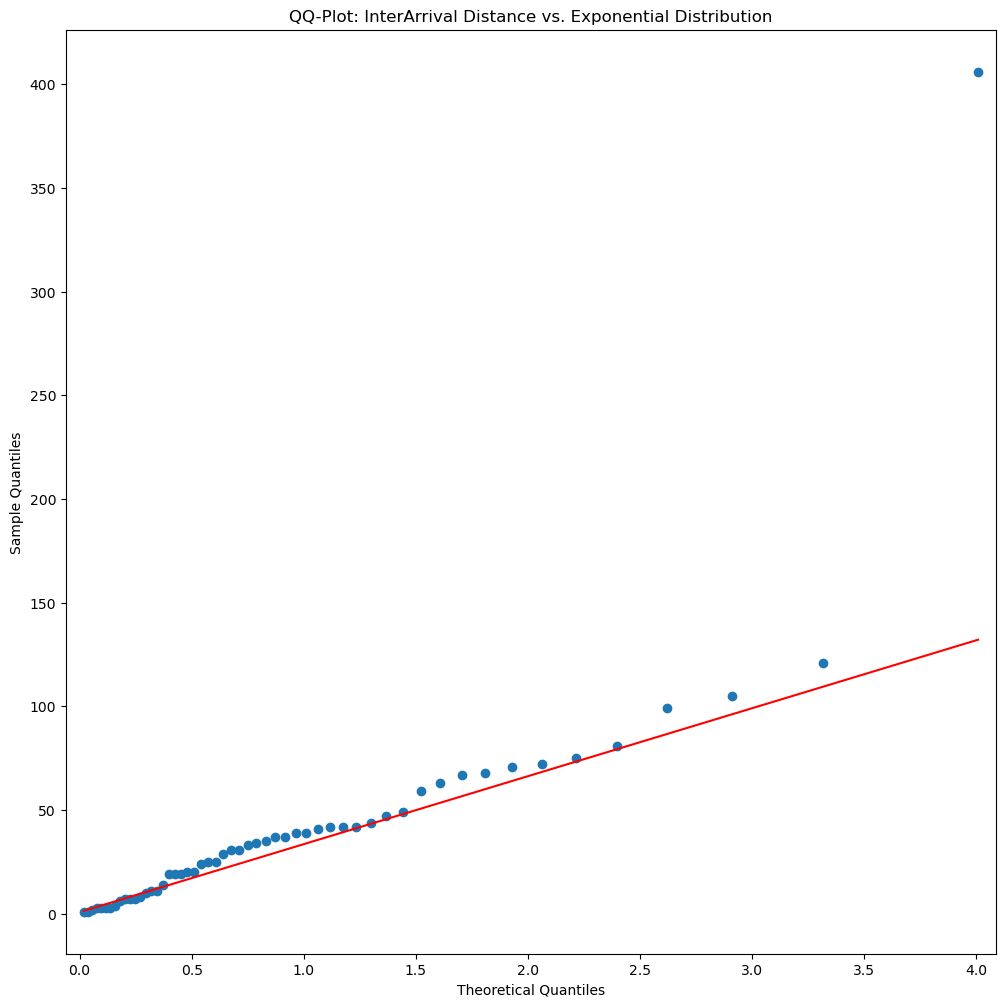


Average ES Real and Theoretical:  2846671.8022518684 2335268.6398527105
ES t-Test significance of difference:  0.017518504818899383  | Reject if <0.05




In [241]:
# For each period we find amount of VaR violations

GARCH = GARCH_portfolio_variance(ind_loss, weights = weights)
ES_GARCH = Var_Cov_ES(GARCH, alpha, stats.norm)
VaR_GARCH = pd.DataFrame(GARCH_VaR(GARCH, alpha, stats.norm.ppf), index = ind_loss.index)[window_size:]         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
ES_GARCH = pd.DataFrame(ES_GARCH, index = ind_loss.index)[window_size:]                                         # ARTIFICIALY DROP FIRST VALUES TO COMPARE
VaR = VaR_GARCH.iloc[:, 0]
ES = ES_GARCH.iloc[:, 0]

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)

### EWMA - Filtered Historical Simulation


Variance Covariance Normal | VaR0.99 | period=2013 | Trading Days=194
Expected number of VaR violations: 1.9400000000000017

VaR Violations:  3

Average ES Real and Theoretical:  1681335.3907378044 1556420.4941923162
ES t-Test significance of difference:  0.6122837938425649  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2014 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  2

Average ES Real and Theoretical:  1738709.9778138888 1785294.3661322524
ES t-Test significance of difference:  0.13767478606671793  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2015 | Trading Days=252
Expected number of VaR violations: 2.5200000000000022

VaR Violations:  3

Average ES Real and Theoretical:  3226363.700777449 3010811.028278249
ES t-Test significance of difference:  0.34007235392630064  | Reject if <0.05



Variance Covariance Normal | VaR0.99 | period=2016 | Trading Days=252
Expected number of VaR violations: 2.5

C:\Users\PAOvi\AppData\Local\Temp\ipykernel_10008\2642011679.py:64: RuntimeWarning: divide by zero encountered in scalar divide
  Z_Test_ES = (np.abs(average_Real_ES - average_Theoretical_ES)) / standard_error
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\PAOvi\anaconda3\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


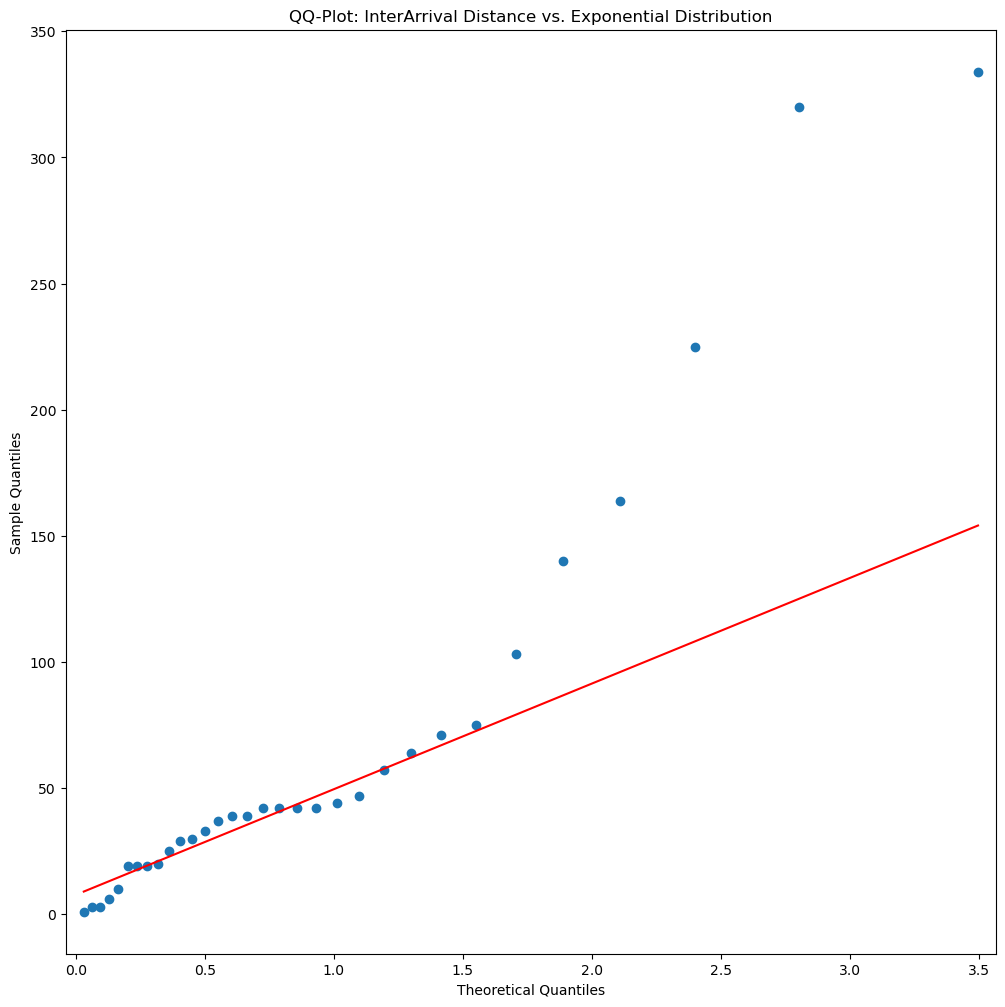


Average ES Real and Theoretical:  2915048.655568857 2714044.087612918
ES t-Test significance of difference:  0.5488046133961662  | Reject if <0.05




In [242]:
# For each period we find amount of VaR violations

EWMA_HS = filtered_HS(ind_loss, weights, alpha, window_size)
VaR_Filtered_Historical = EWMA_HS.VaR
ES_Filtered_Historical = EWMA_HS.ES
VaR = VaR_Filtered_Historical
ES = ES_Filtered_Historical

# We need to cover all years one by one, as some of them had different trading days amount
for i in range(0, len(indexes_year_changes)-1):
    start   = indexes_year_changes[i]
    end     = indexes_year_changes[i+1]
    print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=' +str(2013+i)+ ' | Trading Days=' +str(end-start))
    print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
    Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha)

# And same for the whole year
start   = indexes_year_changes[0]
end     = indexes_year_changes[-1]
print('\nVariance Covariance Normal | VaR' +str(alpha)+ ' | period=Overall | Trading Days=' +str(end-start))
print("Expected number of VaR violations: " + str((end-start) * (1-alpha)))
Backtest(VaR[start:end].to_numpy(), ES[start:end].to_numpy(), portfolio_loss_backtest[start:end], alpha, qqplot_arrival=True)